# B0 — Kiểm toán sample rate, băng thông nguồn WAV và zero-padding

**Tài liệu độc lập — không train, không lựa chọn seed hay Front-End.** Phần này tách khỏi B để không ngắt luồng *OFAT → tổ hợp → quyết định*.

Các bảng dựa trên metadata WAV gốc, nên sample rate nguồn 4 kHz và 44,1 kHz phải được phân biệt với **sample rate chuẩn hóa 16 kHz** ở pipeline C4. Resampling lên 16 kHz không thể khôi phục thông tin vượt Nyquist nguồn 4 kHz (2 kHz). Nếu phân bố nguồn WAV gắn mạnh với nhãn Asthma/Non-Asthma, đó là **nguy cơ sai lệch nguồn**, không tự động là dấu hiệu bệnh.

**Liên kết:** A mô phỏng đáp ứng DSP; B0 kiểm tra nguồn WAV; B/C/C_Extend kiểm chứng thí nghiệm. Kết luận B0 chỉ áp dụng cho tập metadata đang được đọc; tránh suy rộng từ subset sang toàn bộ dataset.

## 0. Thiết lập đường dẫn

Chạy trực tiếp trong repo có `results/B0_dataset_audit/`, hoặc khai báo `NCKH_FRONTEND_DIR`. Chỉ khi muốn đọc *header* WAV Test raw mới đặt `NCKH_DATASET_V2_DIR` về thư mục dataset phù hợp. Thiếu dữ liệu, notebook thông báo thiếu chứ không tự tạo kết quả.


In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def locate_root():
    overrides = [os.environ.get('NCKH_FRONTEND_DIR'), os.environ.get('FRONTEND_BENCHMARK_ROOT')]
    paths = [Path(p).expanduser() for p in overrides if p]
    here=Path.cwd().resolve()
    paths += [here, *here.parents]
    for p in paths:
        for candidate in (p, p/'Frontend_Benchmarking',
            p/'Experiments_Benchmarking'/'Patient_Node'/'Frontend_Benchmarking'):
            if (candidate/'results'/'B0_dataset_audit'/'file_metadata.csv').is_file():
                return candidate.resolve()
    return None
ROOT=locate_root()
B0_DIR=ROOT/'results'/'B0_dataset_audit' if ROOT is not None else None
def read_optional_csv(path):
    return pd.read_csv(path, encoding='utf-8-sig') if path is not None and path.is_file() else pd.DataFrame()
meta=read_optional_csv(B0_DIR/'file_metadata.csv' if B0_DIR else None)
errors=read_optional_csv(B0_DIR/'metadata_errors.csv' if B0_DIR else None)
manifest_path=B0_DIR/'audit_manifest.json' if B0_DIR else None
manifest=json.loads(manifest_path.read_text(encoding='utf-8')) if manifest_path and manifest_path.is_file() else {}
print('B0 root:', ROOT or 'CHƯA CÓ dữ liệu repo; kết quả đã lưu là snapshot lịch sử')
print('Metadata rows:',len(meta),'| lỗi metadata:',len(errors))


B0 root: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking
Metadata rows: 2128 | lỗi metadata: 0


## 1. Kiểm kê thành phần nguồn của Train/Validation
Báo cáo phân bố `raw`, `playback`, `augmentation`, `environment`. Không suy diễn tất cả WAV đại diện cho các bệnh nhân độc lập hoặc cùng điều kiện thu.


In [2]:
if meta.empty:
    print('CHỜ B0: thiếu file_metadata.csv')
else:
    found_splits = set(meta['split'].astype(str))
    print('Train/Val only:', found_splits <= {'train', 'val'}, '| Metadata lỗi:', len(errors))
    if manifest:
        print('Đọc Test:', manifest.get('test_accessed'),
              '| Decode waveform:', manifest.get('waveforms_decoded'))
    source_table = pd.crosstab(
        [meta['split'], meta['label_name']], meta['source_kind']
    ).reindex(columns=['raw','playback','augmentation','environment'], fill_value=0)
    source_table['Tổng WAV'] = source_table.sum(axis=1)
    display(source_table.rename(columns={
        'raw':'Raw', 'playback':'Playback',
        'augmentation':'Augmentation', 'environment':'Environment'
    }).rename_axis(index=['Split','Nhãn']))
    print('Kết luận đọc bảng: cân bằng nhãn ở Train ≠ cân bằng về nguồn ghi.')


Train/Val only: True | Metadata lỗi: 0
Đọc Test: False | Decode waveform: False


source_kind       Raw  Playback  Augmentation  Environment  Tổng WAV
Split Nhãn                                                          
train Asthma      228        64           695            0       987
      Non-Asthma  653        64             0          270       987
val   Asthma       30         8             0            0        38
      Non-Asthma   78         8             0           30       116

Kết luận đọc bảng: cân bằng nhãn ở Train ≠ cân bằng về nguồn ghi.


### B0.2 Tần số lấy mẫu ban đầu (WAV raw)

**Phạm vi biểu đồ:** WAV **raw** trên Train/Validation; header raw Test được đọc riêng **chỉ để audit hậu nghiệm**, không chạy model. Đặc biệt, 4 kHz tập trung ở Asthma và 44,1 kHz tập trung ở Non-Asthma trong nhiều phân hoạch; đây là nguy cơ *source-rate/label confounding*, chưa chứng minh model dùng shortcut. Resampling lên 16 kHz **không phục hồi** phần phổ vắng ở nguồn 4 kHz.

Hình bên dưới giữ nguyên code/hình B0.2 gốc. Nếu không đặt `NCKH_DATASET_V2_DIR`, phần Test sẽ hiển thị thiếu dữ liệu thay vì giả lập số liệu.


,Split,Nhãn,RAW (n),4 kHz - n (%),"44,1 kHz - n (%)",Khác - n
0,train,Asthma,228,205 (89.91%),23 (10.09%),0
1,train,Non-Asthma,653,165 (25.27%),488 (74.73%),0
2,val,Asthma,30,30 (100.00%),0 (0.00%),0
3,val,Non-Asthma,78,1 (1.28%),77 (98.72%),0
4,test,Asthma,30,27 (90.00%),3 (10.00%),0
5,test,Non-Asthma,83,37 (44.58%),46 (55.42%),0


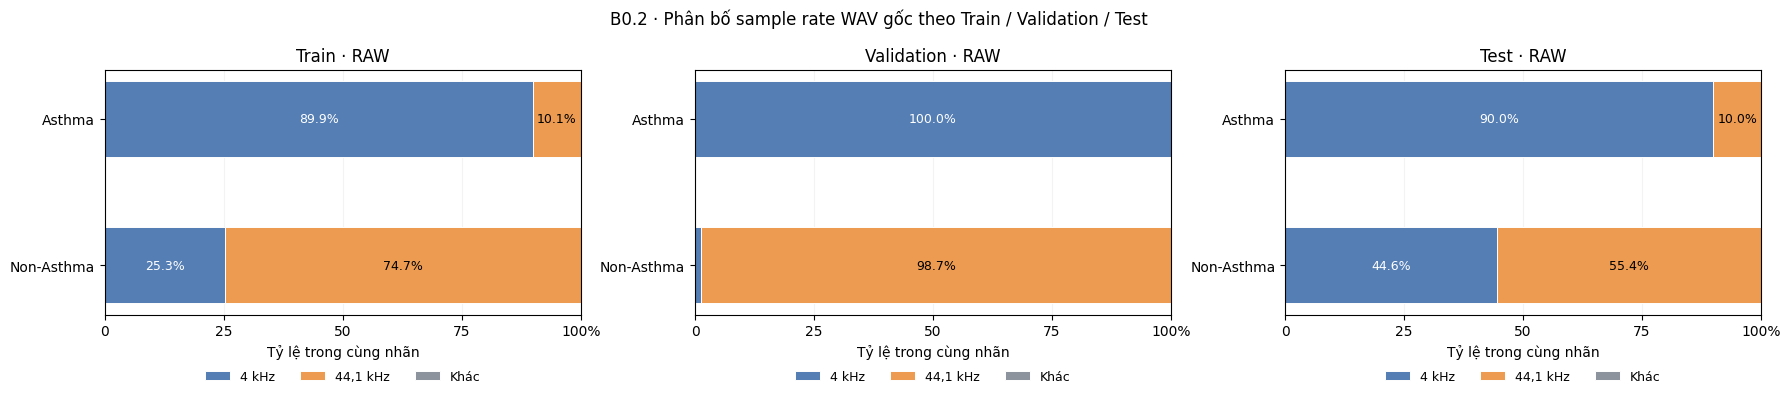

Đã đọc header raw Test: 113 WAV
Lỗi metadata raw Test: 0
Đã lưu biểu đồ B0.2: D:\NCKH_2026\NCKH_2026_AIOT\Experiments_Benchmarking\Patient_Node\Frontend_Benchmarking\results\B0_dataset_audit\figures\B0_2_raw_sampling_rate_train_val_test.png
Đọc kết luận B0.2: so sánh phân bố source rate của cả ba split; không suy diễn thành Accuracy.


In [3]:
if meta.empty:
    print('CHỜ B0: chưa có metadata sample rate.')
else:
    import soundfile as sf

    raw = meta[meta['source_kind'].astype(str).eq('raw')].copy()

    # Bổ sung raw Test trực tiếp vào B0.2 bằng cách chỉ đọc WAV header.
    # Không đọc waveform, không preprocess và không inference trên Test.
    search_starts = []
    if ROOT is not None:
        search_starts.extend([ROOT, *ROOT.parents])
    cwd = Path.cwd().resolve()
    search_starts.extend([cwd, *cwd.parents])
    explicit_ds = os.environ.get('NCKH_DATASET_V2_DIR')
    dataset_v2_root = None
    if explicit_ds:
        check = Path(explicit_ds).expanduser().resolve()
        if ((check / 'Asthma' / 'test').is_dir() and
            (check / 'Non_Asthma_Disease' / 'test').is_dir()):
            dataset_v2_root = check
        else:
            print('NCKH_DATASET_V2_DIR chưa đúng thư mục Dataset_Chia_V2:', check)
    visited = set()
    for base in search_starts:
        for candidate in (
            base / 'AI_Training_Model' / 'Dataset_Chia_V2',
            base / 'Dataset_Chia_V2',
        ):
            candidate = candidate.resolve()
            if candidate in visited:
                continue
            visited.add(candidate)
            if ((candidate / 'Asthma' / 'test').is_dir() and
                    (candidate / 'Non_Asthma_Disease' / 'test').is_dir()):
                dataset_v2_root = candidate
                break
        if dataset_v2_root is not None:
            break

    test_rows, test_metadata_failures = [], []
    if dataset_v2_root is None:
        print('CHƯA TÌM THẤY Dataset_Chia_V2: cột Test sẽ để trống.')
    else:
        test_class_dirs = {
            'Asthma': dataset_v2_root / 'Asthma' / 'test',
            'Non-Asthma': dataset_v2_root / 'Non_Asthma_Disease' / 'test',
        }
        for label, test_dir in test_class_dirs.items():
            for wav_path in sorted(test_dir.glob('*.wav')):
                stem = wav_path.stem.casefold()
                if (stem.endswith(('__take01', '__take02')) or
                        stem.startswith(('env__', 'augv2__'))):
                    continue
                try:
                    info = sf.info(str(wav_path))
                    test_rows.append({
                        'split': 'test',
                        'label_name': label,
                        'original_sr_hz': int(info.samplerate),
                    })
                except Exception as exc:
                    test_metadata_failures.append((str(wav_path), str(exc)))

    if test_rows:
        raw = pd.concat([raw, pd.DataFrame(test_rows)], ignore_index=True, sort=False)

    all_tables = []
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.3), sharex=True)
    plot_specs = (
        ('train', 'Train · RAW'),
        ('val', 'Validation · RAW'),
        ('test', 'Test · RAW'),
    )
    for ax, (sp, title) in zip(axes, plot_specs):
        sub = raw[raw['split'].eq(sp)]
        if sub.empty:
            ax.text(.5,.5,'Không có RAW metadata',ha='center',va='center',transform=ax.transAxes)
            continue
        cnt = pd.crosstab(sub['label_name'], sub['original_sr_hz'])
        cnt.columns = cnt.columns.astype(int)
        cnt = cnt.reindex(index=['Asthma','Non-Asthma'],fill_value=0)
        # Xử lý mọi SR xuất hiện; chỉ gom các mức khác để tránh ẩn dữ liệu ngoài 4k/44.1k.
        c4 = cnt.get(4000, pd.Series(0,index=cnt.index))
        c44 = cnt.get(44100,pd.Series(0,index=cnt.index))
        other = cnt.sum(axis=1)-c4-c44
        cols = pd.DataFrame({'4 kHz': c4, '44,1 kHz': c44, 'Khác': other},index=cnt.index)
        totals = cols.sum(axis=1)
        pct = cols.div(totals.replace(0,np.nan),axis=0).fillna(0).mul(100)
        for label in cols.index:
            all_tables.append({
                'Split':sp, 'Nhãn':label, 'RAW (n)':int(totals[label]),
                '4 kHz - n (%)':f'{int(cols.loc[label,"4 kHz"])} ({pct.loc[label,"4 kHz"]:.2f}%)',
                '44,1 kHz - n (%)':f'{int(cols.loc[label,"44,1 kHz"])} ({pct.loc[label,"44,1 kHz"]:.2f}%)',
                'Khác - n':int(cols.loc[label,'Khác'])})
        y = np.arange(len(cols))
        left = np.zeros(len(cols))
        for key, color in [('4 kHz','#547eb4'),('44,1 kHz','#ed9b50'),('Khác','#8d939d')]:
            val = pct[key].to_numpy()
            ax.barh(y,val,left=left,height=.52,label=key,color=color,edgecolor='white',linewidth=.7)
            for j,v in enumerate(val):
                if v >= 8:
                    ax.text(left[j]+v/2,y[j],f'{v:.1f}%',ha='center',va='center',fontsize=9,color='white' if key=='4 kHz' else 'black')
            left += val
        ax.set_yticks(y,cols.index)
        ax.invert_yaxis();ax.set_xlim(0,100)
        ax.set_xticks([0,25,50,75,100],['0','25','50','75','100%'])
        ax.set_title(title);ax.set_xlabel('Tỷ lệ trong cùng nhãn')
        ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)
        ax.legend(loc='upper center',bbox_to_anchor=(.5,-.18),ncol=3,frameon=False,fontsize=9)
    display(pd.DataFrame(all_tables))
    fig.suptitle('B0.2 · Phân bố sample rate WAV gốc theo Train / Validation / Test', fontsize=12)
    fig.subplots_adjust(left=.07,right=.99,top=.84,bottom=.27,wspace=.24)

    figure_dir = (
        ROOT / 'results' / 'B0_dataset_audit' / 'figures'
        if ROOT is not None
        else Path.cwd() / 'results' / 'B0_dataset_audit' / 'figures'
    )
    figure_dir.mkdir(parents=True, exist_ok=True)
    figure_path = figure_dir / 'B0_2_raw_sampling_rate_train_val_test.png'
    fig.savefig(figure_path, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Đã đọc header raw Test: {len(test_rows):,} WAV'.replace(',', '.'))
    print(f'Lỗi metadata raw Test: {len(test_metadata_failures)}')
    print('Đã lưu biểu đồ B0.2:', figure_path)
    print('Đọc kết luận B0.2: so sánh phân bố source rate của cả ba split; không suy diễn thành Accuracy.')


### B0.3 Kiểm kê zero-padding cửa sổ 5 giây (tùy chọn)
Kiểm tra tỷ lệ đệm zero trên Train/Validation; nếu tìm được Dataset V2 thì đọc thêm **header Test**, chỉ để mô tả nguy cơ dữ liệu. Không tự loại WAV chỉ vì thời lượng ngắn.


In [4]:
if meta.empty:
    print('CHỜ B0: thiếu metadata padding.')
else:
    import soundfile as sf

    # Giữ nguyên metadata Train/Validation của B0_Dataset_Audit và chỉ bổ sung
    # header Test vào bản sao dùng riêng cho B0.3.
    padding_meta = meta.copy()
    search_starts = []
    if ROOT is not None:
        search_starts.extend([ROOT, *ROOT.parents])
    cwd = Path.cwd().resolve()
    search_starts.extend([cwd, *cwd.parents])
    explicit_ds = os.environ.get('NCKH_DATASET_V2_DIR')
    padding_dataset_root = None
    if explicit_ds:
        check = Path(explicit_ds).expanduser().resolve()
        if ((check / 'Asthma' / 'test').is_dir() and
            (check / 'Non_Asthma_Disease' / 'test').is_dir()):
            padding_dataset_root = check
        else:
            print('NCKH_DATASET_V2_DIR chưa đúng thư mục Dataset_Chia_V2:', check)
    visited = set()
    for base in search_starts:
        for candidate in (
            base / 'AI_Training_Model' / 'Dataset_Chia_V2',
            base / 'Dataset_Chia_V2',
        ):
            candidate = candidate.resolve()
            if candidate in visited:
                continue
            visited.add(candidate)
            if ((candidate / 'Asthma' / 'test').is_dir() and
                    (candidate / 'Non_Asthma_Disease' / 'test').is_dir()):
                padding_dataset_root = candidate
                break
        if padding_dataset_root is not None:
            break

    test_padding_rows, test_padding_errors = [], []
    if padding_dataset_root is None:
        print('CHƯA TÌM THẤY Dataset_Chia_V2: B0.3 tạm thời chỉ có Train/Validation.')
    else:
        test_class_dirs = {
            'Asthma': padding_dataset_root / 'Asthma' / 'test',
            'Non-Asthma': padding_dataset_root / 'Non_Asthma_Disease' / 'test',
        }
        for label_name, test_dir in test_class_dirs.items():
            for wav_path in sorted(test_dir.glob('*.wav')):
                try:
                    info = sf.info(str(wav_path))
                    stem = wav_path.stem.casefold()
                    if stem.endswith(('__take01', '__take02')):
                        source_kind, offset = 'playback', 1.0
                    elif stem.startswith('augv2__'):
                        source_kind, offset = 'augmentation', 0.0
                    elif stem.startswith('env__'):
                        source_kind, offset = 'environment', 0.0
                    else:
                        source_kind, offset = 'raw', 0.0
                    duration = float(info.duration)
                    usable = min(max(duration - offset, 0.0), 5.0)
                    pad_seconds = max(0.0, 5.0 - usable)
                    pad_pct = 100.0 * pad_seconds / 5.0
                    test_padding_rows.append({
                        'file': f"{test_dir.parent.name}/test/{wav_path.name}",
                        'split': 'test',
                        'label_name': label_name,
                        'source_kind': source_kind,
                        'original_sr_hz': int(info.samplerate),
                        'original_duration_s': duration,
                        'v1_offset_s': offset,
                        'v1_window_s': 5.0,
                        'usable_duration_s': usable,
                        'estimated_zero_pad_s': pad_seconds,
                        'estimated_zero_pad_pct': pad_pct,
                        'requires_padding': int(pad_seconds > 1e-9),
                    })
                except Exception as exc:
                    test_padding_errors.append((str(wav_path), str(exc)))

    if test_padding_rows:
        padding_meta = pd.concat(
            [padding_meta, pd.DataFrame(test_padding_rows)],
            ignore_index=True, sort=False,
        )

    pad_rows = []
    for sp in ('train', 'val', 'test'):
        for lab in ('Asthma', 'Non-Asthma'):
            s = padding_meta[
                padding_meta['split'].astype(str).eq(sp)
                & padding_meta['label_name'].astype(str).eq(lab)
            ]
            if s.empty:
                continue
            p = pd.to_numeric(s['estimated_zero_pad_pct'], errors='coerce').fillna(0)
            n = len(s)
            n_low = int(((p > 0) & (p < 50)).sum())
            n_mid = int(((p >= 50) & (p < 80)).sum())
            n_high = int((p >= 80).sum())
            n_any = n_low + n_mid + n_high
            pad_rows.append({
                'Split': sp, 'Nhãn': lab, 'WAV': n,
                'Cần đệm - n (%)': f'{n_any} ({100*n_any/n:.2f}%)',
                'Đệm <50%': n_low, 'Đệm 50–<80%': n_mid,
                'Đệm ≥80%': n_high, 'Không đệm': n-n_any,
            })
    pad_overview = pd.DataFrame(pad_rows)
    display(pad_overview)
    n_total = int(pad_overview['WAV'].sum())
    n_pad = int(sum(int(v.split(' ')[0]) for v in pad_overview['Cần đệm - n (%)']))
    print(f'Tổng: {n_pad}/{n_total} WAV ({100*n_pad/n_total:.2f}%) cần đệm; '
          'chỉ báo rủi ro dữ liệu, không tự động loại khỏi Train/Val/Test.')
    print(f'Đã đọc header Test: {len(test_padding_rows)} WAV; lỗi: {len(test_padding_errors)}')


,Split,Nhãn,WAV,Cần đệm - n (%),Đệm <50%,Đệm 50–<80%,Đệm ≥80%,Không đệm
0,train,Asthma,987,9 (0.91%),5,1,3,978
1,train,Non-Asthma,987,11 (1.11%),9,2,0,976
2,val,Asthma,38,0 (0.00%),0,0,0,38
3,val,Non-Asthma,116,3 (2.59%),3,0,0,113
4,test,Asthma,38,0 (0.00%),0,0,0,38
5,test,Non-Asthma,121,1 (0.83%),0,1,0,120


Tổng: 24/2287 WAV (1.05%) cần đệm; chỉ báo rủi ro dữ liệu, không tự động loại khỏi Train/Val/Test.
Đã đọc header Test: 159 WAV; lỗi: 0


## B0.4 Kết luận và phạm vi sử dụng

Đưa vào báo cáo: thống kê sample rate **trước resampling**, so sánh theo nguồn và nhãn khi metadata cho phép, kiểm tra số giây bị padding, và giới hạn Nyquist. Không dùng phân bố sample rate để khẳng định một bệnh có dải tần đặc trưng cụ thể.

**Bàn giao:** xem A để hiểu bộ lọc/FFT/Mel; mở **B** để bắt đầu 9 phép thử OFAT (F0, seed 42). Notebook này không được chép bảng Accuracy hay kết luận s44 vào phần dữ liệu nguồn.